# Adult Census Income - tuned-model evaluation


## 1. Imports and paths


In [15]:
from pathlib import Path
import time
import gc
import json
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from catboost import CatBoostClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss,
    precision_recall_curve, roc_curve, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score,
    balanced_accuracy_score
)
from sklearn.calibration import calibration_curve

PROJECT_ROOT = Path(r"C:\Case Study Trees\AdultCensusStudy")
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
TRAINING_RESULTS = PROJECT_ROOT / "results"
EVAL_DIR = TRAINING_RESULTS / "adult_evaluation"
FIGURE_DIR = EVAL_DIR / "figures"
PREDICTION_DIR = EVAL_DIR / "predictions"

for folder in [EVAL_DIR, FIGURE_DIR, PREDICTION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
THREADS = 4
TIMING_BATCH_ROWS = 1000
TIMING_REPEATS = 7
N_BOOTSTRAPS = 300
sns.set_theme(style="whitegrid")

## 2. Find models and saved metadata


In [16]:
model_specs = [
    ("rf", "Random Forest", "One-hot"),
    ("lgb", "LightGBM", "Native"),
    ("cat", "CatBoost", "Native")
]

xgb_required = [
    ARTIFACT_DIR / "adult_xgb_tuned.joblib",
    ARTIFACT_DIR / "adult_xgb_input_info.joblib",
    TRAINING_RESULTS / "xgb_tuned_validation.csv"
]
if all(path.exists() for path in xgb_required):
    model_specs.append(("xgb", "XGBoost", "Native"))
else:
    print("XGBoost excluded: no complete saved XGBoost pipeline was found.")
    for path in xgb_required:
        if not path.exists():
            print("  Missing:", path.name)

records = []
for key, name, representation in model_specs:
    model_path = ARTIFACT_DIR / f"adult_{key}_tuned.joblib"
    metrics_path = TRAINING_RESULTS / f"{key}_tuned_validation.csv"
    for path in [model_path, metrics_path]:
        if not path.exists():
            raise FileNotFoundError(path)
    saved = pd.read_csv(metrics_path)
    assert len(saved) == 1
    if representation == "Native":
        info_path = ARTIFACT_DIR / f"adult_{key}_input_info.joblib"
        if not info_path.exists():
            raise FileNotFoundError(info_path)
    records.append({
        "Key": key, "Model": name, "Representation": representation,
        "Model_Path": str(model_path),
        "Recorded_Validation_AUC": float(saved.iloc[0]["Validation_ROC_AUC"]),
        "Fit_Seconds": float(saved.iloc[0]["Fit_Seconds"]),
        "Tuning_Seconds": float(saved.iloc[0]["Tuning_Seconds"])
    })
registry = pd.DataFrame(records)
registry.to_csv(EVAL_DIR / "model_registry.csv", index=False)
display(registry)
print("Number of tuned models:", len(registry))

onehot_preprocessor = joblib.load(ARTIFACT_DIR / "adult_onehot_preprocessor.joblib")
native_preprocessor = joblib.load(ARTIFACT_DIR / "adult_native_preprocessor.joblib")

,Key,Model,Representation,Model_Path,Recorded_Validation_AUC,Fit_Seconds,Tuning_Seconds
0,rf,Random Forest,One-hot,C:\Case Study Trees\AdultCensusStudy\artifacts...,0.918839,2.749310,605.180411
1,lgb,LightGBM,Native,C:\Case Study Trees\AdultCensusStudy\artifacts...,0.931385,1.510743,600.253225
2,cat,CatBoost,Native,C:\Case Study Trees\AdultCensusStudy\artifacts...,0.929679,36.199908,624.665751
3,xgb,XGBoost,Native,C:\Case Study Trees\AdultCensusStudy\artifacts...,0.932459,1.194551,601.706719


Number of tuned models: 4


## 3. Reuse the fitted input rules


In [17]:
def load_inputs(split, key):
    frame = pd.read_csv(SPLIT_DIR / f"{split}.csv")
    assert frame["ROW_ID"].notna().all() and frame["ROW_ID"].is_unique
    target = frame["income"].copy()
    ids = frame["ROW_ID"].copy()
    assert target.notna().all() and target.isin([0, 1]).all()
    raw = frame.drop(columns=["income", "ROW_ID", "education", "fnlwgt"])

    if key == "rf":
        data = onehot_preprocessor.transform(raw).astype("float32")
        readable_names = onehot_preprocessor.get_feature_names_out().tolist()
    else:
        info = joblib.load(ARTIFACT_DIR / f"adult_{key}_input_info.joblib")
        names = native_preprocessor.get_feature_names_out().tolist()
        assert names == info["original_columns"]
        data = pd.DataFrame(native_preprocessor.transform(raw), columns=names, index=raw.index)
        data[info["numeric_columns"]] = data[info["numeric_columns"]].astype("float32")
        for column in info["categorical_columns"]:
            values = data[column].astype(str)
            levels = info["category_levels"][column]
            values = values.where(values.isin(levels), "Missing")
            if key in ["lgb", "xgb"]:
                data[column] = pd.Categorical(values, categories=levels)
            else:
                data[column] = values
        readable_names = names
        data.columns = info["model_columns"]

    numeric = data if key == "rf" else data.select_dtypes(include="number").to_numpy()
    assert np.isfinite(numeric).all()
    assert len(data) == len(target)
    return data, target, ids, readable_names


def load_model(record, data):
    model = joblib.load(record["Model_Path"])
    if isinstance(model, CatBoostClassifier):
        assert model.tree_count_ > 0, "CatBoost contains no trained trees."
        expected = len(model.feature_names_)
        assert model.feature_names_ == data.columns.tolist()
    else:
        expected = model.n_features_in_
        if isinstance(data, pd.DataFrame):
            if record["Key"] == "lgb":
                assert model.booster_.feature_name() == data.columns.tolist()
            elif record["Key"] == "xgb":
                assert model.get_booster().feature_names == data.columns.tolist()
    assert expected == data.shape[1], f"{record['Model']}: feature-count mismatch"
    # Fix inference worker count without changing fitted trees.
    if record["Key"] in ["rf", "xgb"]:
        model.set_params(n_jobs=THREADS)
    return model


def predict_probability(model, data, key):
    if key == "cat":
        probability = model.predict_proba(data, thread_count=THREADS)[:, 1]
    elif key == "lgb":
        probability = model.predict_proba(data, num_threads=THREADS)[:, 1]
    else:
        probability = model.predict_proba(data)[:, 1]
    assert np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    return probability

## 4. Validation: reproduce scores, freeze thresholds and measure inference
.

In [18]:
validation_predictions = {}
validation_rows = []
valid_ids_reference = None
valid_y_reference = None

for _, record in registry.iterrows():
    print("Validation:", record["Model"], flush=True)
    data, target, ids, names = load_inputs("valid", record["Key"])
    if valid_ids_reference is None:
        valid_ids_reference = ids.copy()
        valid_y_reference = target.copy()
    else:
        pd.testing.assert_series_equal(ids, valid_ids_reference)
        pd.testing.assert_series_equal(target, valid_y_reference)
    model = load_model(record, data)
    probability = predict_probability(model, data, record["Key"])
    validation_predictions[record["Key"]] = probability
    auc = roc_auc_score(target, probability)
    if not np.isclose(auc, record["Recorded_Validation_AUC"], atol=1e-5, rtol=0):
        raise ValueError(f"{record['Model']}: loaded validation AUC {auc:.6f} differs from saved {record['Recorded_Validation_AUC']:.6f}")

    precision, recall, thresholds = precision_recall_curve(target, probability)
    f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    threshold = float(thresholds[np.argmax(f1_values)])

    batch = data[:min(TIMING_BATCH_ROWS, len(data))]
    predict_probability(model, batch, record["Key"])
    durations = []
    for repeat in range(TIMING_REPEATS):
        start = time.perf_counter()
        predict_probability(model, batch, record["Key"])
        durations.append(time.perf_counter() - start)
    scale = 1000 / len(batch)
    validation_rows.append({
        "Key": record["Key"], "Threshold": threshold,
        "Validation_ROC_AUC": auc, "Validation_AP": average_precision_score(target, probability),
        "Validation_F1": float(np.max(f1_values)), "Timing_Batch_Rows": len(batch),
        "Prediction_Seconds_Per_1000": float(np.median(durations) * scale),
        "Prediction_P25_Seconds_Per_1000": float(np.percentile(durations, 25) * scale),
        "Prediction_P75_Seconds_Per_1000": float(np.percentile(durations, 75) * scale)
    })
    pd.DataFrame({"ROW_ID": ids, "income": target, "Probability": probability}).to_csv(
        PREDICTION_DIR / f"{record['Key']}_validation_predictions.csv", index=False
    )
    del data, model
    gc.collect()

validation_results = pd.DataFrame(validation_rows)
registry = registry.drop(columns=[c for c in validation_results if c != "Key"], errors="ignore")
registry = registry.merge(validation_results, on="Key", validate="one_to_one")
registry.to_csv(EVAL_DIR / "frozen_validation_decisions.csv", index=False)
validation_selected_key = registry.loc[registry["Validation_ROC_AUC"].idxmax(), "Key"]
(EVAL_DIR / "validation_selected_model.json").write_text(json.dumps({"Key": validation_selected_key}))
display(registry[["Model", "Threshold", "Validation_ROC_AUC", "Validation_AP", "Validation_F1", "Prediction_Seconds_Per_1000"]])
print("Validation-selected representative:", validation_selected_key)

Validation: Random Forest
Validation: LightGBM
Validation: CatBoost
Validation: XGBoost


,Model,Threshold,Validation_ROC_AUC,Validation_AP,Validation_F1,Prediction_Seconds_Per_1000
0,Random Forest,0.586283,0.918839,0.804247,0.712652,0.081601
1,LightGBM,0.413243,0.931385,0.832734,0.734970,0.056031
2,CatBoost,0.430536,0.929679,0.828152,0.734904,0.008815
3,XGBoost,0.402557,0.932459,0.833992,0.739967,0.009495


Validation-selected representative: xgb


## 5. Final test evaluation


In [19]:
test_predictions = {}
test_rows = []
y_test = None
test_ids_reference = None

for _, record in registry.iterrows():
    print("Test:", record["Model"], flush=True)
    data, target, ids, names = load_inputs("test", record["Key"])
    if y_test is None:
        y_test = target.to_numpy()
        test_ids_reference = ids.copy()
        assert set(ids).isdisjoint(valid_ids_reference)
        train_ids = pd.read_csv(SPLIT_DIR / "train.csv")["ROW_ID"]
        assert set(ids).isdisjoint(train_ids)
    else:
        np.testing.assert_array_equal(target.to_numpy(), y_test)
        pd.testing.assert_series_equal(ids, test_ids_reference)
    model = load_model(record, data)
    probability = predict_probability(model, data, record["Key"])
    test_predictions[record["Key"]] = probability
    prediction = (probability >= record["Threshold"]).astype(int)
    default_prediction = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
    order = np.argsort(-probability, kind="stable")
    top_count = max(1, int(np.ceil(0.1 * len(target))))
    top_positives = y_test[order[:top_count]].sum()

    result = record.to_dict()
    result.update({
        "Dataset": "Adult Income", "Version": "Tuned", "Test_Rows": len(target),
        "Positive_Prevalence": target.mean(),
        "ROC_AUC": roc_auc_score(y_test, probability),
        "Average_Precision": average_precision_score(y_test, probability),
        "Log_Loss": log_loss(y_test, probability, labels=[0, 1]),
        "Brier_Score": np.mean((probability - y_test) ** 2),
        "Accuracy": accuracy_score(y_test, prediction),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "Recall": recall_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction, zero_division=0),
        "Flagged_Percentage": prediction.mean() * 100,
        "Accuracy_At_0_5": accuracy_score(y_test, default_prediction),
        "F1_At_0_5": f1_score(y_test, default_prediction, zero_division=0),
        "Recall_At_Top_10_Percent": top_positives / y_test.sum(),
        "Lift_At_Top_10_Percent": (top_positives / top_count) / target.mean(),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Model_Size_MiB": Path(record["Model_Path"]).stat().st_size / 1024 ** 2
    })
    test_rows.append(result)
    pd.DataFrame({"ROW_ID": ids, "income": target, "Probability": probability,
                  "Threshold": record["Threshold"], "Prediction": prediction}).to_csv(
        PREDICTION_DIR / f"{record['Key']}_test_predictions.csv", index=False
    )
    del model, data
    gc.collect()

results = pd.DataFrame(test_rows)
results.to_csv(EVAL_DIR / "adult_test_results.csv", index=False)
display(results[["Model", "Representation", "ROC_AUC", "Average_Precision", "Log_Loss", "Brier_Score",
                 "Accuracy", "Balanced_Accuracy", "Precision", "Recall", "F1"]].sort_values("ROC_AUC", ascending=False).round(4))
print("Test applicants:", len(y_test))
print("Income >50K prevalence:", round(float(np.mean(y_test)), 4))
print("All-negative accuracy:", round(float(1 - np.mean(y_test)), 4))

Test: Random Forest
Test: LightGBM
Test: CatBoost
Test: XGBoost


,Model,Representation,ROC_AUC,Average_Precision,Log_Loss,Brier_Score,Accuracy,Balanced_Accuracy,Precision,Recall,F1
1,LightGBM,Native,0.9231,0.8251,0.2864,0.0903,0.8664,0.8154,0.7255,0.7168,0.7211
3,XGBoost,Native,0.9228,0.8242,0.2876,0.0905,0.8613,0.8123,0.7098,0.7177,0.7137
2,CatBoost,Native,0.9211,0.8219,0.2895,0.0911,0.8646,0.8075,0.7289,0.6973,0.7127
0,Random Forest,One-hot,0.9127,0.8024,0.3556,0.1169,0.8433,0.8187,0.6465,0.7713,0.7034


Test applicants: 4881
Income >50K prevalence: 0.2409
All-negative accuracy: 0.7591


## 6. Paired bootstrap uncertainty


In [20]:
rng = np.random.default_rng(SEED)
positive_positions = np.flatnonzero(y_test == 1)
negative_positions = np.flatnonzero(y_test == 0)
bootstrap_auc = {key: [] for key in test_predictions}
bootstrap_ap = {key: [] for key in test_predictions}

for repeat in range(N_BOOTSTRAPS):
    positions = np.r_[
        rng.choice(positive_positions, len(positive_positions), replace=True),
        rng.choice(negative_positions, len(negative_positions), replace=True)
    ]
    for key, probability in test_predictions.items():
        bootstrap_auc[key].append(roc_auc_score(y_test[positions], probability[positions]))
        bootstrap_ap[key].append(average_precision_score(y_test[positions], probability[positions]))

intervals = []
for key in test_predictions:
    intervals.append({
        "Key": key,
        "AUC_Lower": np.percentile(bootstrap_auc[key], 2.5),
        "AUC_Upper": np.percentile(bootstrap_auc[key], 97.5),
        "AP_Lower": np.percentile(bootstrap_ap[key], 2.5),
        "AP_Upper": np.percentile(bootstrap_ap[key], 97.5)
    })
results = results.drop(columns=["AUC_Lower", "AUC_Upper", "AP_Lower", "AP_Upper"], errors="ignore")
results = results.merge(pd.DataFrame(intervals), on="Key", validate="one_to_one")
results.to_csv(EVAL_DIR / "adult_test_results_with_intervals.csv", index=False)

paired_rows = []
for a, b in combinations(test_predictions, 2):
    for metric, samples in [("ROC_AUC", bootstrap_auc), ("Average_Precision", bootstrap_ap)]:
        differences = np.array(samples[b]) - np.array(samples[a])
        scores = results.set_index("Key")[metric]
        paired_rows.append({"Model_A": a, "Model_B": b, "Metric": metric,
                            "Difference_B_Minus_A": scores[b] - scores[a],
                            "Lower": np.percentile(differences, 2.5), "Upper": np.percentile(differences, 97.5)})
paired_results = pd.DataFrame(paired_rows)
paired_results.to_csv(EVAL_DIR / "adult_paired_differences.csv", index=False)
display(paired_results.round(4))

,Model_A,Model_B,Metric,Difference_B_Minus_A,Lower,Upper
0,rf,lgb,ROC_AUC,0.0104,0.0078,0.0131
1,rf,lgb,Average_Precision,0.0228,0.0153,0.0301
2,rf,cat,ROC_AUC,0.0084,0.0057,0.0116
3,rf,cat,Average_Precision,0.0195,0.0131,0.0268
4,rf,xgb,ROC_AUC,0.0101,0.0071,0.0133
5,rf,xgb,Average_Precision,0.0218,0.0147,0.0288
6,lgb,cat,ROC_AUC,-0.0020,-0.0036,-0.0005
7,lgb,cat,Average_Precision,-0.0032,-0.0068,-0.0001
8,lgb,xgb,ROC_AUC,-0.0003,-0.0015,0.0010
9,lgb,xgb,Average_Precision,-0.0010,-0.0040,0.0025


## 7. Plot settings


In [21]:
labels = results.set_index("Key")["Model"].to_dict()
colors = {"rf": "#64748b", "lgb": "#168b87", "cat": "#a66bbe", "xgb": "#e57851"}

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()

## 8. Ranking and positive-case retrieval


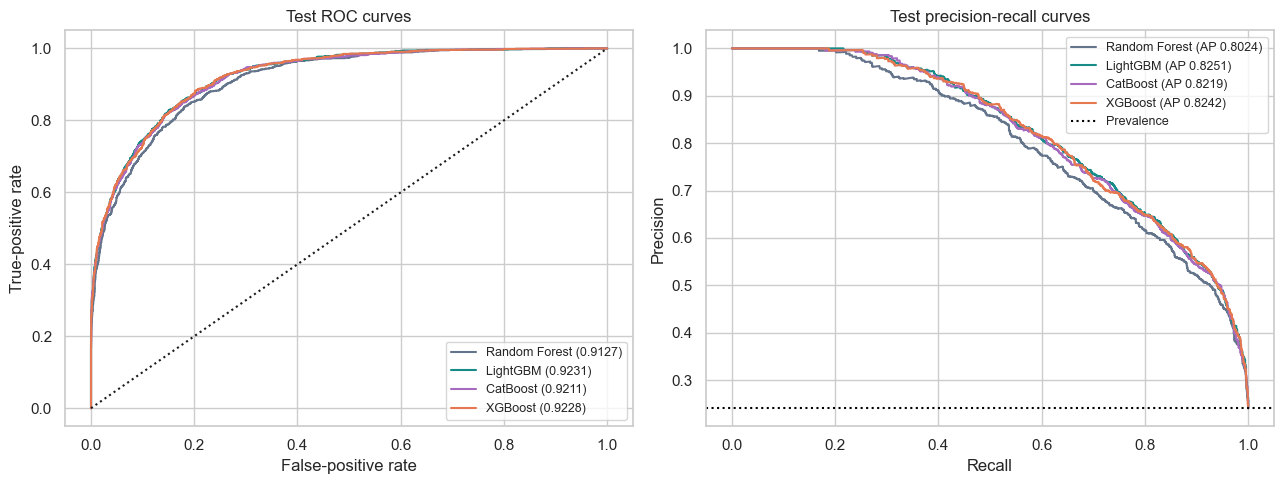

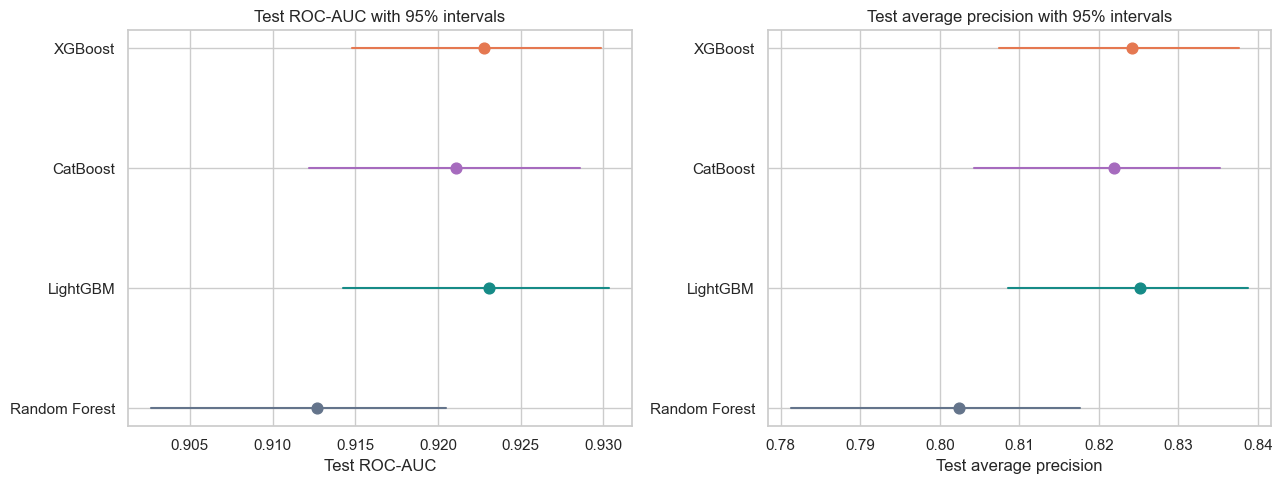

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for _, row in results.iterrows():
    key = row["Key"]
    fpr, tpr, _ = roc_curve(y_test, test_predictions[key])
    precision, recall, _ = precision_recall_curve(y_test, test_predictions[key])
    axes[0].plot(fpr, tpr, color=colors[key], label=f"{row['Model']} ({row['ROC_AUC']:.4f})")
    axes[1].plot(recall, precision, color=colors[key], label=f"{row['Model']} (AP {row['Average_Precision']:.4f})")
axes[0].plot([0, 1], [0, 1], "k:")
axes[0].set(title="Test ROC curves", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].axhline(np.mean(y_test), color="black", linestyle=":", label="Prevalence")
axes[1].set(title="Test precision-recall curves", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(fontsize=9)
save_figure("01_roc_and_precision_recall")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, low, high, title in [
    (axes[0], "ROC_AUC", "AUC_Lower", "AUC_Upper", "Test ROC-AUC"),
    (axes[1], "Average_Precision", "AP_Lower", "AP_Upper", "Test average precision")
]:
    for position, (_, row) in enumerate(results.iterrows()):
        ax.plot([row[low], row[high]], [position, position], color=colors[row["Key"]])
        ax.scatter(row[metric], position, color=colors[row["Key"]], s=60)
    ax.set_yticks(range(len(results)), results["Model"])
    ax.set(title=title + " with 95% intervals", xlabel=title)
save_figure("02_auc_ap_intervals")

## 9. Calibration and probability quality


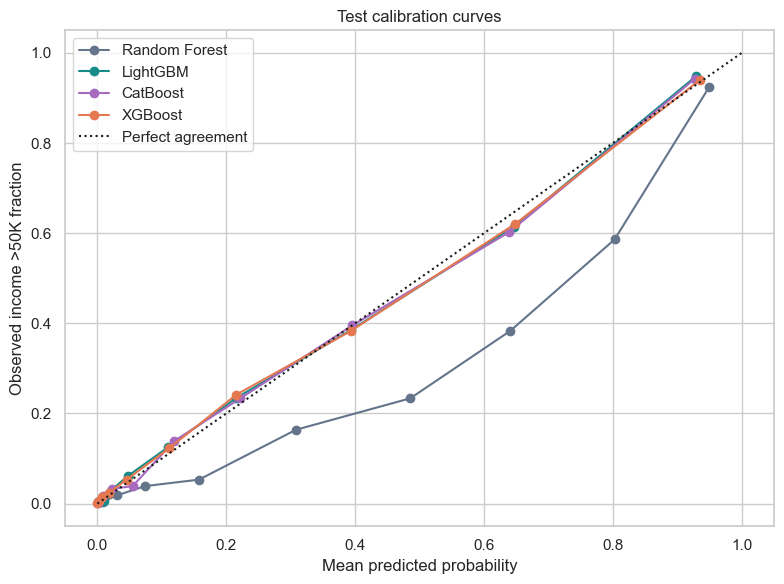

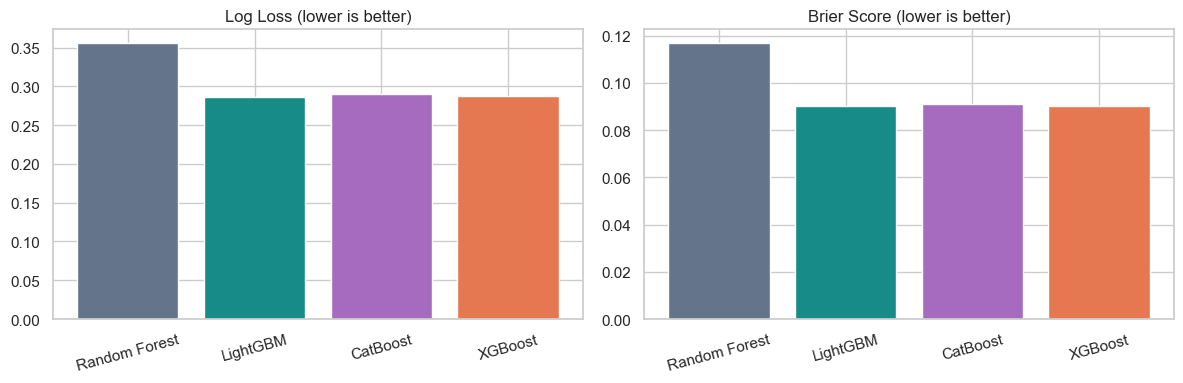

In [23]:
plt.figure(figsize=(8, 6))
for _, row in results.iterrows():
    key = row["Key"]
    probability = test_predictions[key]
    observed, predicted = calibration_curve(y_test, probability, n_bins=10, strategy="quantile")
    plt.plot(predicted, observed, marker="o", color=colors[key], label=row["Model"])
    bins = pd.DataFrame({"Probability": probability, "income": y_test})
    bins["Bin"] = pd.qcut(bins["Probability"], q=10, duplicates="drop")
    bins.groupby("Bin", observed=True).agg(
        Applicants=("income", "size"), Predicted=("Probability", "mean"), Observed=("income", "mean")
    ).to_csv(EVAL_DIR / f"{key}_calibration_bins.csv")
plt.plot([0, 1], [0, 1], "k:", label="Perfect agreement")
plt.title("Test calibration curves")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed income >50K fraction")
plt.legend()
save_figure("03_calibration")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in [(axes[0], "Log_Loss"), (axes[1], "Brier_Score")]:
    ax.bar(results["Model"], results[metric], color=[colors[k] for k in results["Key"]])
    ax.set_title(metric.replace("_", " ") + " (lower is better)")
    ax.tick_params(axis="x", rotation=15)
save_figure("04_probability_quality")

## 10. Threshold choice and classification errors


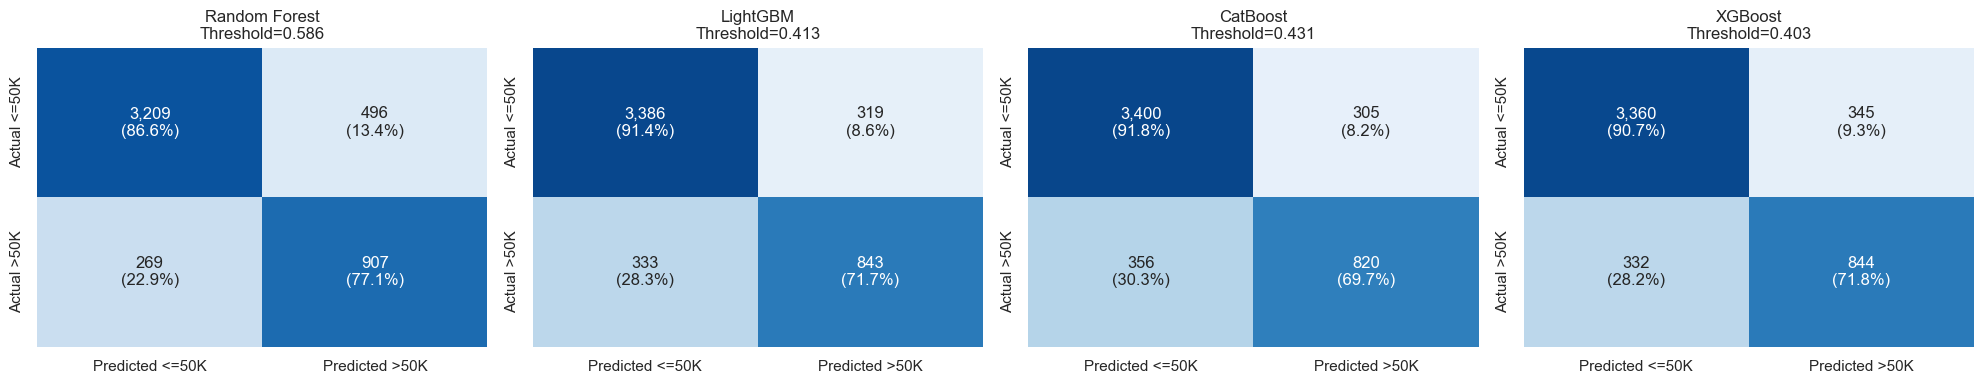

,Model,Threshold,Precision,Recall,F1,Accuracy,Balanced_Accuracy,Flagged_Percentage,F1_At_0_5,Accuracy_At_0_5
0,Random Forest,0.5863,0.6465,0.7713,0.7034,0.8433,0.8187,28.7441,0.6941,0.8218
1,LightGBM,0.4132,0.7255,0.7168,0.7211,0.8664,0.8154,23.8066,0.7066,0.8697
2,CatBoost,0.4305,0.7289,0.6973,0.7127,0.8646,0.8075,23.0486,0.7013,0.8681
3,XGBoost,0.4026,0.7098,0.7177,0.7137,0.8613,0.8123,24.3598,0.7086,0.8709


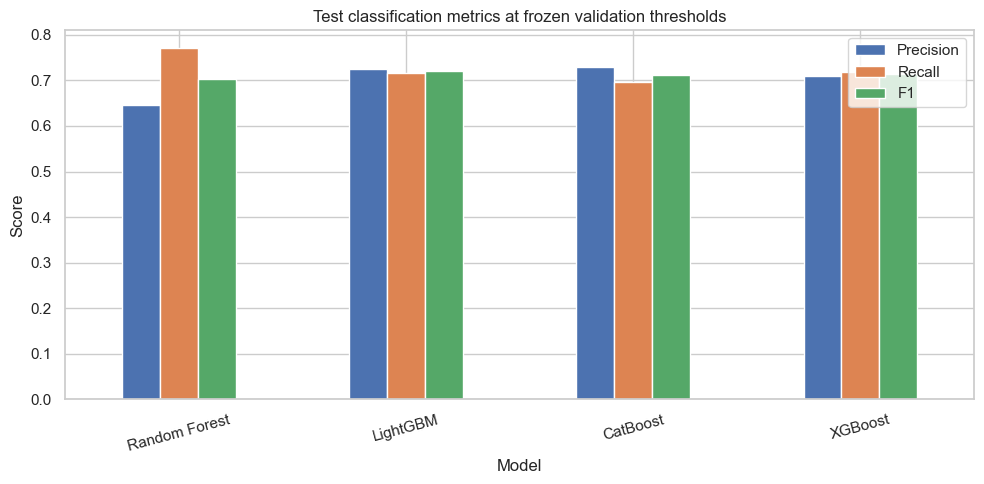

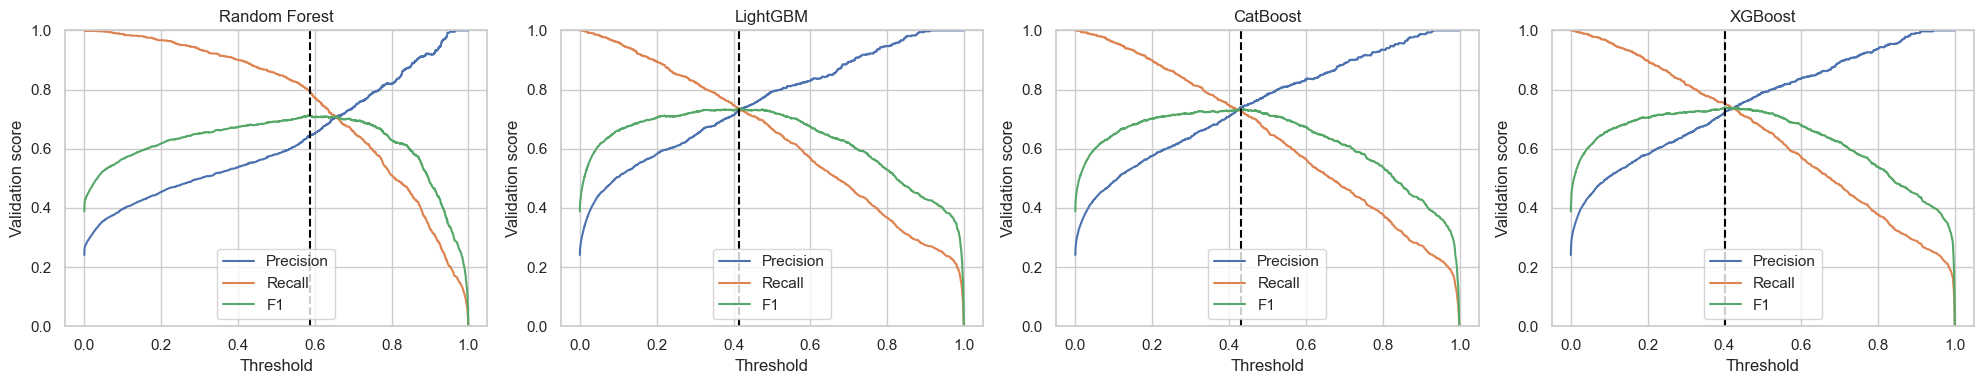

In [24]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
axes = np.atleast_1d(axes)
for ax, (_, row) in zip(axes, results.iterrows()):
    matrix = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]], dtype=int)
    fractions = matrix / matrix.sum(axis=1, keepdims=True)
    annotations = np.array([[f"{matrix[i,j]:,}\n({fractions[i,j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(fractions, annot=annotations, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=["Predicted <=50K", "Predicted >50K"],
                yticklabels=["Actual <=50K", "Actual >50K"], ax=ax)
    ax.set_title(f"{row['Model']}\nThreshold={row['Threshold']:.3f}")
save_figure("05_confusion_matrices")

decisions = results[["Model", "Threshold", "Precision", "Recall", "F1", "Accuracy", "Balanced_Accuracy", "Flagged_Percentage", "F1_At_0_5", "Accuracy_At_0_5"]]
display(decisions.round(4))
decisions.to_csv(EVAL_DIR / "adult_threshold_comparison.csv", index=False)
results.set_index("Model")[["Precision", "Recall", "F1"]].plot.bar(figsize=(10, 5), rot=15)
plt.title("Test classification metrics at frozen validation thresholds")
plt.ylabel("Score")
save_figure("06_precision_recall_f1")

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
for ax, (_, row) in zip(np.atleast_1d(axes), results.iterrows()):
    p, r, thresholds = precision_recall_curve(valid_y_reference, validation_predictions[row["Key"]])
    f = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-15)
    ax.plot(thresholds, p[:-1], label="Precision")
    ax.plot(thresholds, r[:-1], label="Recall")
    ax.plot(thresholds, f, label="F1")
    ax.axvline(row["Threshold"], color="black", linestyle="--")
    ax.set(title=row["Model"], xlabel="Threshold", ylabel="Validation score", ylim=(0, 1))
    ax.legend()
save_figure("07_validation_threshold_sensitivity")

## 11. Ranking at a fixed capacity


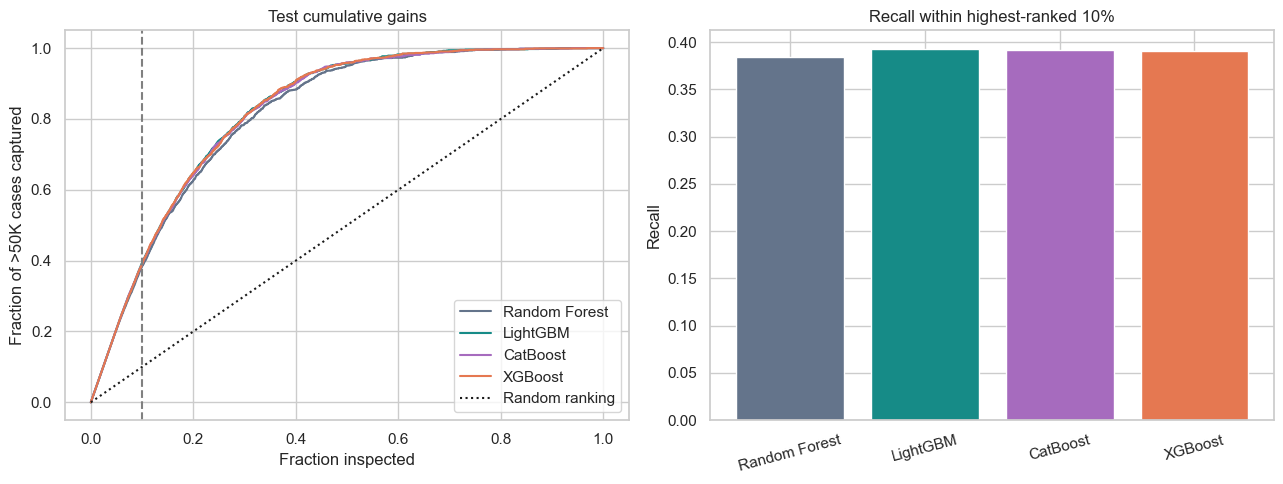

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for _, row in results.iterrows():
    order = np.argsort(-test_predictions[row["Key"]], kind="stable")
    fraction = np.arange(1, len(y_test) + 1) / len(y_test)
    captured = np.cumsum(y_test[order]) / y_test.sum()
    axes[0].plot(np.r_[0, fraction], np.r_[0, captured], color=colors[row["Key"]], label=row["Model"])
axes[0].plot([0, 1], [0, 1], "k:", label="Random ranking")
axes[0].axvline(0.1, color="gray", linestyle="--")
axes[0].set(title="Test cumulative gains", xlabel="Fraction inspected", ylabel="Fraction of >50K cases captured")
axes[0].legend()
axes[1].bar(results["Model"], results["Recall_At_Top_10_Percent"], color=[colors[k] for k in results["Key"]])
axes[1].set(title="Recall within highest-ranked 10%", ylabel="Recall")
axes[1].tick_params(axis="x", rotation=15)
save_figure("08_cumulative_gains_and_top10")

## 12. Speed, tuning cost and file size


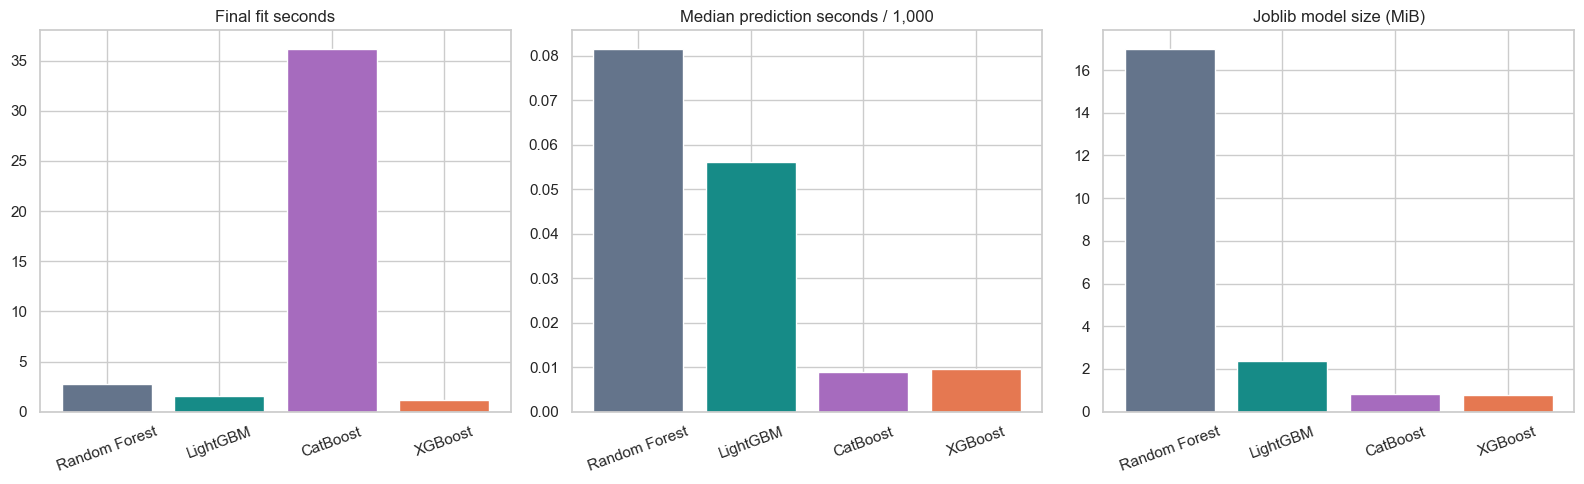

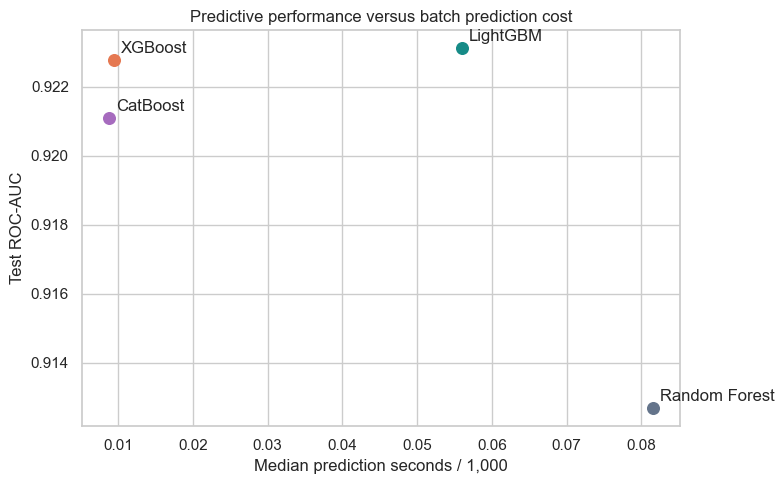

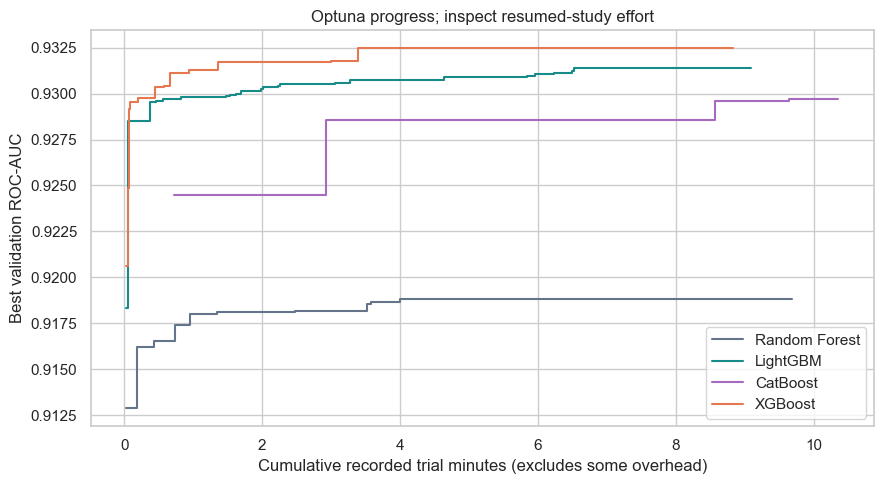

,Model,Completed_Trials,Recorded_Trial_Seconds,Last_Recorded_Session_Seconds
0,Random Forest,153,581.409976,605.180411
1,LightGBM,331,545.887350,600.253225
2,CatBoost,18,621.560985,624.665751
3,XGBoost,372,530.038348,601.706719


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric, title in [
    (axes[0], "Fit_Seconds", "Final fit seconds"),
    (axes[1], "Prediction_Seconds_Per_1000", "Median prediction seconds / 1,000"),
    (axes[2], "Model_Size_MiB", "Joblib model size (MiB)")
]:
    ax.bar(results["Model"], results[metric], color=[colors[k] for k in results["Key"]])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
save_figure("09_compute_and_size")

plt.figure(figsize=(8, 5))
for _, row in results.iterrows():
    plt.scatter(row["Prediction_Seconds_Per_1000"], row["ROC_AUC"], color=colors[row["Key"]], s=70)
    plt.annotate(row["Model"], (row["Prediction_Seconds_Per_1000"], row["ROC_AUC"]), xytext=(5, 5), textcoords="offset points")
plt.xlabel("Median prediction seconds / 1,000")
plt.ylabel("Test ROC-AUC")
plt.title("Predictive performance versus batch prediction cost")
save_figure("10_quality_vs_inference_cost")

trial_summary = []
plt.figure(figsize=(9, 5))
for _, row in results.iterrows():
    key = row["Key"]
    filename = "cat_10min_optuna_trials.csv" if key == "cat" else f"{key}_optuna_trials.csv"
    path = TRAINING_RESULTS / filename
    if not path.exists():
        print("Trial file unavailable:", filename)
        continue
    trials = pd.read_csv(path).sort_values("number")
    duration = (pd.to_datetime(trials["datetime_complete"]) - pd.to_datetime(trials["datetime_start"])).dt.total_seconds()
    trials["Minutes"] = duration.fillna(0).clip(lower=0).cumsum() / 60
    complete = trials[trials["state"] == "COMPLETE"]
    if not complete.empty:
        plt.step(complete["Minutes"], complete["value"].cummax(), where="post", label=row["Model"], color=colors[key])
    trial_summary.append({"Model": row["Model"], "Completed_Trials": len(complete),
                          "Recorded_Trial_Seconds": duration.sum(), "Last_Recorded_Session_Seconds": row["Tuning_Seconds"]})
plt.xlabel("Cumulative recorded trial minutes (excludes some overhead)")
plt.ylabel("Best validation ROC-AUC")
plt.title("Optuna progress; inspect resumed-study effort")
plt.legend()
save_figure("11_optuna_progress")
pd.DataFrame(trial_summary).to_csv(EVAL_DIR / "adult_tuning_effort.csv", index=False)
display(pd.DataFrame(trial_summary))

## 13. Feature importance


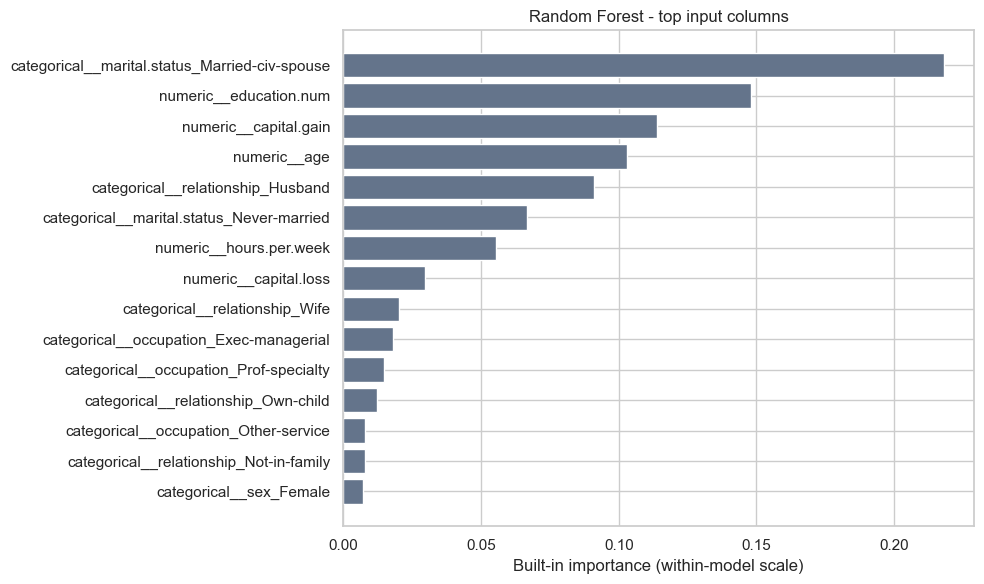

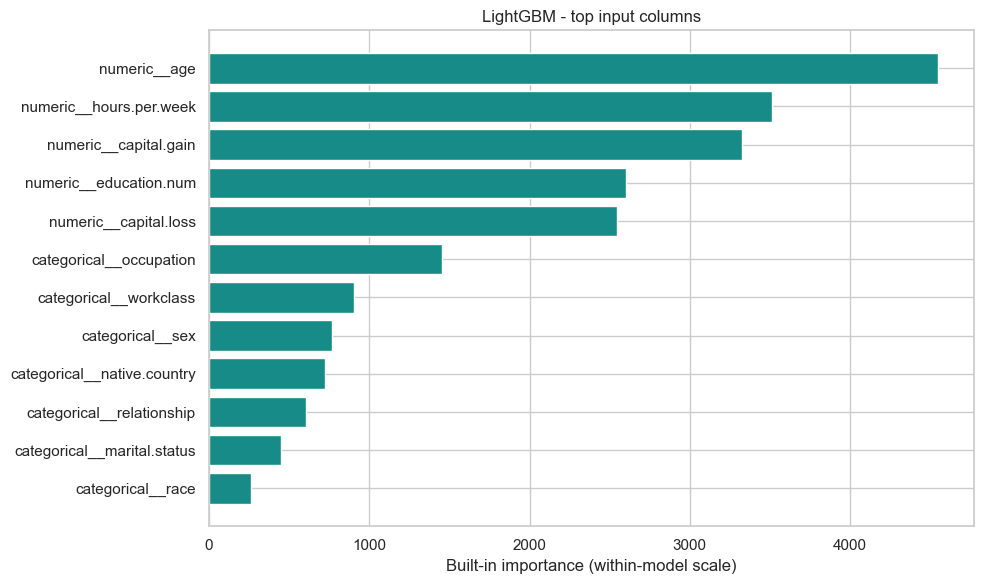

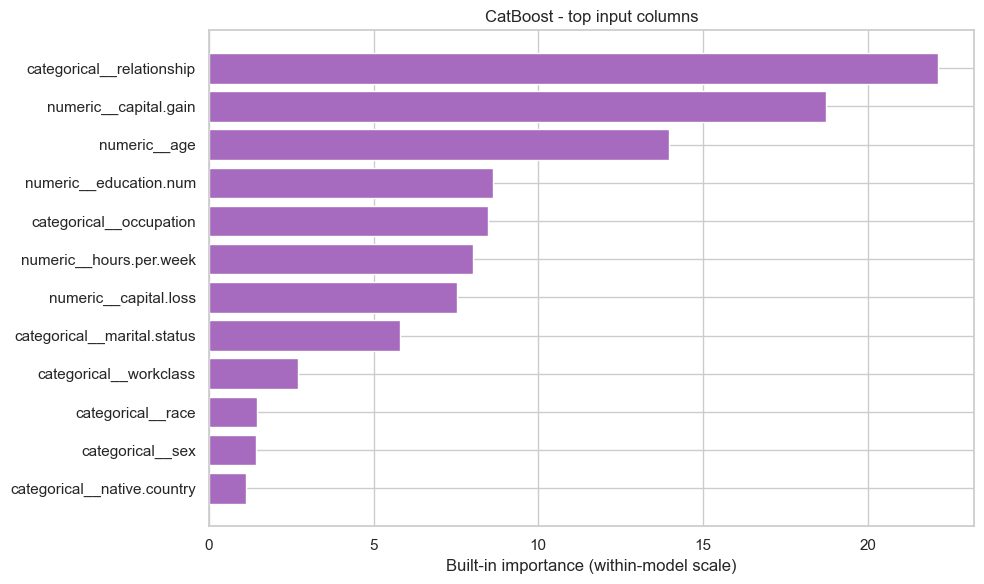

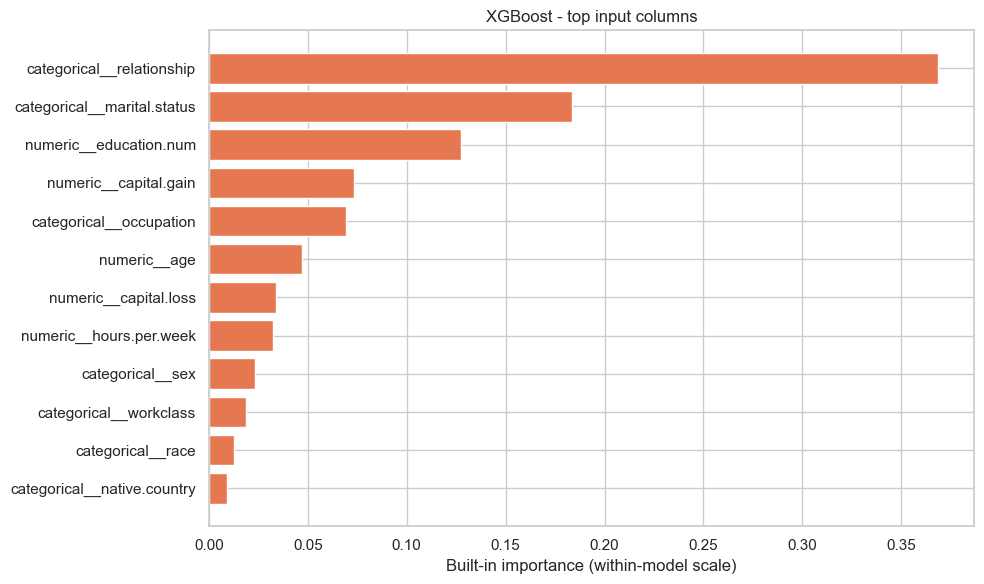

In [ ]:
for _, record in registry.iterrows():
    if record["Key"] == "rf":
        names = onehot_preprocessor.get_feature_names_out().tolist()
    else:
        info = joblib.load(ARTIFACT_DIR / f"adult_{record['Key']}_input_info.joblib")
        names = info["original_columns"]
    model = joblib.load(record["Model_Path"])
    importance = np.asarray(model.feature_importances_)
    assert len(importance) == len(names)
    table = pd.DataFrame({"Feature": names, "Importance": importance}).sort_values("Importance", ascending=False)
    table.to_csv(EVAL_DIR / f"{record['Key']}_feature_importance.csv", index=False)
    plot_data = table.head(15).sort_values("Importance")
    plt.figure(figsize=(10, 6))
    plt.barh(plot_data["Feature"], plot_data["Importance"], color=colors[record["Key"]])
    plt.xlabel("Built-in importance (within-model scale)")
    plt.title(record["Model"] + " - top input columns")
    save_figure(f"12_importance_{record['Key']}")
    del model
    gc.collect()

## 14. Summarize without overclaiming


In [29]:
columns = [
    "Dataset", "Model", "Representation", "Version", "ROC_AUC", "AUC_Lower", "AUC_Upper",
    "Average_Precision", "Log_Loss", "Brier_Score", "Accuracy", "Balanced_Accuracy",
    "Threshold", "Precision", "Recall", "F1", "Recall_At_Top_10_Percent",
    "Fit_Seconds", "Tuning_Seconds", "Prediction_Seconds_Per_1000", "Model_Size_MiB"
]
results[columns].to_csv(EVAL_DIR / "adult_final_master_table.csv", index=False)
display(results[columns].sort_values("ROC_AUC", ascending=False).round(4))

highest_observed = results.loc[results["ROC_AUC"].idxmax()]
selected = results.loc[results["Key"] == validation_selected_key].iloc[0]
print("ADULT INCOME - OBSERVED RESULTS")
print("Evaluated pipelines:", len(results))
print(f"Highest observed test AUC: {highest_observed['Model']} = {highest_observed['ROC_AUC']:.4f}")
print(f"Validation-selected pipeline: {selected['Model']}")
print(f"Its test AUC = {selected['ROC_AUC']:.4f}, AP = {selected['Average_Precision']:.4f}, F1 = {selected['F1']:.4f}")


,Dataset,Model,Representation,Version,ROC_AUC,AUC_Lower,AUC_Upper,Average_Precision,Log_Loss,Brier_Score,...,Balanced_Accuracy,Threshold,Precision,Recall,F1,Recall_At_Top_10_Percent,Fit_Seconds,Tuning_Seconds,Prediction_Seconds_Per_1000,Model_Size_MiB
1,Adult Income,LightGBM,Native,Tuned,0.9231,0.9143,0.9303,0.8251,0.2864,0.0903,...,0.8154,0.4132,0.7255,0.7168,0.7211,0.3929,1.5107,600.2532,0.0560,2.3594
3,Adult Income,XGBoost,Native,Tuned,0.9228,0.9148,0.9298,0.8242,0.2876,0.0905,...,0.8123,0.4026,0.7098,0.7177,0.7137,0.3912,1.1946,601.7067,0.0095,0.7875
2,Adult Income,CatBoost,Native,Tuned,0.9211,0.9122,0.9286,0.8219,0.2895,0.0911,...,0.8075,0.4305,0.7289,0.6973,0.7127,0.3920,36.1999,624.6658,0.0088,0.8280
0,Adult Income,Random Forest,One-hot,Tuned,0.9127,0.9027,0.9205,0.8024,0.3556,0.1169,...,0.8187,0.5863,0.6465,0.7713,0.7034,0.3844,2.7493,605.1804,0.0816,17.0052


ADULT INCOME - OBSERVED RESULTS
Evaluated pipelines: 4
Highest observed test AUC: LightGBM = 0.9231
Validation-selected pipeline: XGBoost
Its test AUC = 0.9228, AP = 0.8242, F1 = 0.7137
